# Análise Exploratória de Dados (EDA)

## NPS e experiência do cliente no e-commerce

**Tech Challenge · Fase 1 · Pós-Tech FIAP — AI Scientist**  
**Notebook oficial da análise exploratória** · Unidade de análise: pedido

## Objetivo e visão geral

Esta análise explora **2.500 pedidos** para entender o que aparece associado ao NPS. A nota média é **4,38**, e **74%** dos pedidos são classificados como detratores. Atrasos e reclamações são os sinais mais ligados a notas baixas. Já a recompra coincide exatamente com uma regra baseada na nota, então não dá para tratá-la como evidência independente de retenção.

O notebook segue uma sequência simples: conferir os dados, definir as categorias de NPS e responder às perguntas do desafio. Os resultados descrevem esta base; associação não prova causa, e não há modelo preditivo nesta entrega.

## Configuração

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import kruskal, linregress, spearmanr

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

NOME_ARQUIVO_DADOS = 'desafio_nps_fase_1.csv'
RAIZ_PROJETO = next(
    (
        pasta for pasta in (Path.cwd(), *Path.cwd().parents)
        if (pasta / 'data' / NOME_ARQUIVO_DADOS).is_file()
    ),
    None,
)
if RAIZ_PROJETO is None:
    raise FileNotFoundError(
        f'Não foi possível localizar data/{NOME_ARQUIVO_DADOS} a partir de {Path.cwd()}'
    )

# Os gráficos também ficam salvos em reports/figures para usar nos slides
PASTA_FIGURAS = RAIZ_PROJETO / 'reports' / 'figures'
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

def salvar_figura(nome):
    plt.savefig(PASTA_FIGURAS / f'{nome}.png', dpi=300, bbox_inches='tight')


# Cores que repeti em todos os gráficos
AZUL, VERMELHO, LARANJA, VERDE = '#4C72B0', '#C44E52', '#DD8452', '#55A868'


def intervalo_wilson(sucessos, total):
    # Intervalo de confiança de 95% para uma proporção (Wilson)
    if total == 0:
        return float('nan'), float('nan')
    z = 1.96
    proporcao = sucessos / total
    denominador = 1 + z**2 / total
    centro = (proporcao + z**2 / (2 * total)) / denominador
    margem = z * (proporcao * (1 - proporcao) / total + z**2 / (4 * total**2)) ** 0.5 / denominador
    return centro - margem, centro + margem


def resumir_grupo(grupo):
    # Para cada grupo: quantos pedidos, nota média e % de detratores com intervalo de confiança
    total = len(grupo)
    detratores = int((grupo['PONTUACAO_NPS'] <= 6).sum())
    limite_inferior, limite_superior = intervalo_wilson(detratores, total)
    return pd.Series({
        'Pedidos': total,
        'NPS médio': grupo['PONTUACAO_NPS'].mean(),
        'Detratores (%)': detratores / total * 100,
        'IC 95% inferior (%)': limite_inferior * 100,
        'IC 95% superior (%)': limite_superior * 100,
    })


def tabela_por_grupo(dados, coluna):
    # Aplica o resumo acima para cada valor de uma coluna (e deixa 'Pedidos' como inteiro)
    tabela = dados.groupby(coluna, observed=True)[['PONTUACAO_NPS']].apply(resumir_grupo)
    tabela['Pedidos'] = tabela['Pedidos'].astype(int)
    return tabela

## 1. Conhecendo os dados

### 1.1 Carregamento e primeira olhada

In [2]:
df = pd.read_csv(RAIZ_PROJETO / 'data' / NOME_ARQUIVO_DADOS, sep=',')
df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [3]:
df_colunas_renomeadas = df.copy()

novos_nomes = {
    'customer_id': 'ID_CLIENTE',
    'customer_age': 'IDADE_CLIENTE',
    'customer_region': 'REGIAO_CLIENTE',
    'customer_tenure_months': 'TEMPO_CLIENTE_MESES',
    'order_id': 'ID_PEDIDO',
    'order_value': 'VALOR_PEDIDO',
    'items_quantity': 'QUANTIDADE_ITENS',
    'discount_value': 'VALOR_DESCONTO',
    'payment_installments': 'PARCELAS_PAGAMENTO',
    'delivery_time_days': 'TEMPO_ENTREGA_DIAS',
    'delivery_delay_days': 'ATRASO_ENTREGA_DIAS',
    'freight_value': 'VALOR_FRETE',
    'delivery_attempts': 'TENTATIVAS_ENTREGA',
    'customer_service_contacts': 'CONTATOS_ATENDIMENTO',
    'resolution_time_days': 'TEMPO_RESOLUCAO_DIAS',
    'nps_score': 'PONTUACAO_NPS',
    'repeat_purchase_30d': 'RECOMPRA_30D',
    'complaints_count': 'CONTAGEM_RECLAMACOES',
    'csat_internal_score': 'PONTUACAO_CSAT_INTERNO'
}

df_colunas_renomeadas = df_colunas_renomeadas.rename(columns = novos_nomes)
df_colunas_renomeadas.head()

,ID_CLIENTE,IDADE_CLIENTE,REGIAO_CLIENTE,TEMPO_CLIENTE_MESES,ID_PEDIDO,VALOR_PEDIDO,QUANTIDADE_ITENS,VALOR_DESCONTO,PARCELAS_PAGAMENTO,TEMPO_ENTREGA_DIAS,ATRASO_ENTREGA_DIAS,VALOR_FRETE,TENTATIVAS_ENTREGA,CONTATOS_ATENDIMENTO,TEMPO_RESOLUCAO_DIAS,PONTUACAO_NPS,RECOMPRA_30D,CONTAGEM_RECLAMACOES,PONTUACAO_CSAT_INTERNO
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [4]:
df_colunas_renomeadas.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_CLIENTE              2500 non-null   int64  
 1   IDADE_CLIENTE           2500 non-null   int64  
 2   REGIAO_CLIENTE          2500 non-null   str    
 3   TEMPO_CLIENTE_MESES     2500 non-null   int64  
 4   ID_PEDIDO               2500 non-null   int64  
 5   VALOR_PEDIDO            2500 non-null   float64
 6   QUANTIDADE_ITENS        2500 non-null   int64  
 7   VALOR_DESCONTO          2500 non-null   float64
 8   PARCELAS_PAGAMENTO      2500 non-null   int64  
 9   TEMPO_ENTREGA_DIAS      2500 non-null   int64  
 10  ATRASO_ENTREGA_DIAS     2500 non-null   int64  
 11  VALOR_FRETE             2500 non-null   float64
 12  TENTATIVAS_ENTREGA      2500 non-null   int64  
 13  CONTATOS_ATENDIMENTO    2500 non-null   int64  
 14  TEMPO_RESOLUCAO_DIAS    2500 non-null   int64  
 15

In [5]:
df_colunas_renomeadas.describe().round(2)

,ID_CLIENTE,IDADE_CLIENTE,TEMPO_CLIENTE_MESES,ID_PEDIDO,VALOR_PEDIDO,QUANTIDADE_ITENS,VALOR_DESCONTO,PARCELAS_PAGAMENTO,TEMPO_ENTREGA_DIAS,ATRASO_ENTREGA_DIAS,VALOR_FRETE,TENTATIVAS_ENTREGA,CONTATOS_ATENDIMENTO,TEMPO_RESOLUCAO_DIAS,PONTUACAO_NPS,RECOMPRA_30D,CONTAGEM_RECLAMACOES,PONTUACAO_CSAT_INTERNO
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,1250.50,43.40,61.32,51250.50,434.26,3.47,29.75,6.00,8.02,2.19,38.22,2.01,1.52,5.49,4.38,0.09,4.15,2.94
std,721.83,14.89,34.48,721.83,289.77,1.69,29.23,3.16,3.77,1.45,12.08,0.82,1.23,3.46,2.51,0.28,1.78,2.38
min,1.00,18.00,1.00,50001.00,7.76,1.00,0.02,1.00,2.00,0.00,2.62,1.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,625.75,31.00,31.00,50625.75,220.24,2.00,8.88,3.00,5.00,1.00,29.93,1.00,1.00,2.00,2.60,0.00,3.00,0.70
50%,1250.50,43.00,62.00,51250.50,375.52,3.00,20.94,6.00,8.00,2.00,38.50,2.00,1.00,6.00,4.40,0.00,4.00,2.80
75%,1875.25,56.00,91.00,51875.25,577.29,5.00,40.83,9.00,11.00,3.00,46.27,3.00,2.00,8.00,6.10,0.00,5.00,4.80
max,2500.00,69.00,119.00,52500.00,1983.81,6.00,230.33,11.00,14.00,8.00,76.13,3.00,7.00,11.00,10.00,1.00,11.00,10.00


### 1.2 Qualidade dos dados

Antes de analisar os resultados, vamos conferir se os dados estão completos e se há valores que precisam de validação. O objetivo aqui é sinalizar problemas, não corrigir campos sem saber qual valor está certo.

In [6]:
colunas_contagem = [
    'TEMPO_CLIENTE_MESES', 'QUANTIDADE_ITENS', 'PARCELAS_PAGAMENTO',
    'TEMPO_ENTREGA_DIAS', 'ATRASO_ENTREGA_DIAS', 'TENTATIVAS_ENTREGA',
    'CONTATOS_ATENDIMENTO', 'TEMPO_RESOLUCAO_DIAS', 'CONTAGEM_RECLAMACOES',
]
verificacoes = pd.Series({
    'Valores ausentes': int(df_colunas_renomeadas.isna().sum().sum()),
    'Linhas duplicadas': int(df_colunas_renomeadas.duplicated().sum()),
    'IDs de cliente repetidos': int(df_colunas_renomeadas['ID_CLIENTE'].duplicated().sum()),
    'IDs de pedido repetidos': int(df_colunas_renomeadas['ID_PEDIDO'].duplicated().sum()),
    'NPS fora da escala de 0 a 10': int((~df_colunas_renomeadas['PONTUACAO_NPS'].between(0, 10)).sum()),
    'Idades fora de 18 a 120 anos': int((~df_colunas_renomeadas['IDADE_CLIENTE'].between(18, 120)).sum()),
    'Contagens negativas': int((df_colunas_renomeadas[colunas_contagem] < 0).any(axis=1).sum()),
    'Recompra fora de 0 ou 1': int((~df_colunas_renomeadas['RECOMPRA_30D'].isin([0, 1])).sum()),
    'Atraso maior que o tempo de entrega': int((df_colunas_renomeadas['ATRASO_ENTREGA_DIAS'] > df_colunas_renomeadas['TEMPO_ENTREGA_DIAS']).sum()),
    'Desconto maior que o valor do pedido': int((df_colunas_renomeadas['VALOR_DESCONTO'] > df_colunas_renomeadas['VALOR_PEDIDO']).sum()),
}, name='Registros sinalizados')
display(verificacoes.to_frame())
print(f'Pedidos: {len(df_colunas_renomeadas):,} | Clientes únicos: {df_colunas_renomeadas["ID_CLIENTE"].nunique():,} | Pedidos únicos: {df_colunas_renomeadas["ID_PEDIDO"].nunique():,}')

,Registros sinalizados
Valores ausentes,0
Linhas duplicadas,0
IDs de cliente repetidos,0
IDs de pedido repetidos,0
NPS fora da escala de 0 a 10,0
Idades fora de 18 a 120 anos,0
Contagens negativas,0
Recompra fora de 0 ou 1,0
Atraso maior que o tempo de entrega,121
Desconto maior que o valor do pedido,35


Pedidos: 2,500 | Clientes únicos: 2,500 | Pedidos únicos: 2,500


In [7]:
# Mais três coisas que me chamaram atenção olhando a tabela acima
sem_reclamacao = int((df_colunas_renomeadas['CONTAGEM_RECLAMACOES'] == 0).sum())
com_decimal = (df_colunas_renomeadas['PONTUACAO_NPS'] % 1 != 0).mean() * 100
rho_tempo_atraso, _ = spearmanr(df_colunas_renomeadas['TEMPO_ENTREGA_DIAS'], df_colunas_renomeadas['ATRASO_ENTREGA_DIAS'])

print(f'Pedidos sem nenhuma reclamação: {sem_reclamacao} ({sem_reclamacao / len(df_colunas_renomeadas) * 100:.1f}%)')
print(f'Notas com casa decimal: {com_decimal:.0f}%')
print(f'Correlação entre tempo total de entrega e atraso (Spearman): {rho_tempo_atraso:.3f}')

Pedidos sem nenhuma reclamação: 23 (0.9%)
Notas com casa decimal: 83%
Correlação entre tempo total de entrega e atraso (Spearman): -0.006


A base tem **2.500 pedidos**, sem valores ausentes, linhas duplicadas ou IDs repetidos. Encontrei dois pontos para validar com a origem: em **121 pedidos**, o atraso informado é maior que o tempo total de entrega; em **35**, o desconto supera o valor do pedido. Mantive os valores como estavam.

Também há três cuidados para o restante da análise:

- **83% das notas têm casas decimais.** Por isso, a regra para classificar detratores, neutros e promotores fica explícita na próxima seção.
- Só **23 pedidos** não têm reclamações registradas; comparações com esse grupo são pouco precisas.
- Tempo total de entrega e atraso quase não se relacionam nesta base (`ρ ≈ −0,006`). Vale confirmar com a fonte o que cada campo representa.

### 1.3 Como classificamos o NPS?

As notas incluem casas decimais. Para comparar os pedidos, vamos usar esta regra sem arredondar a nota original:

- **Detrator:** nota `<= 6`.
- **Neutro:** nota `> 6` e `<= 8`.
- **Promotor:** nota `> 8`.

É a convenção adotada neste trabalho; comparações com outras análises devem usar os mesmos limites.

In [8]:
df_colunas_renomeadas['CATEGORIA_NPS'] = pd.cut(
    df_colunas_renomeadas['PONTUACAO_NPS'],
    bins=[-float('inf'), 6, 8, float('inf')],
    labels=['Detrator', 'Neutro', 'Promotor'],
)

# Marcações simples que uso nas comparações das próximas seções
df_colunas_renomeadas['DETRATOR'] = (df_colunas_renomeadas['PONTUACAO_NPS'] <= 6).astype(int)
df_colunas_renomeadas['TEVE_ATRASO'] = df_colunas_renomeadas['ATRASO_ENTREGA_DIAS'] > 0
df_colunas_renomeadas['TEVE_RECLAMACAO'] = df_colunas_renomeadas['CONTAGEM_RECLAMACOES'] > 0
df_colunas_renomeadas['MAIS_DE_1_TENTATIVA'] = df_colunas_renomeadas['TENTATIVAS_ENTREGA'] > 1

resumo_nps = df_colunas_renomeadas['CATEGORIA_NPS'].value_counts().reindex(['Detrator', 'Neutro', 'Promotor']).to_frame('Pedidos')
resumo_nps['Percentual'] = resumo_nps['Pedidos'] / len(df_colunas_renomeadas) * 100
display(resumo_nps.round(1))

pct_promotores = resumo_nps.loc['Promotor', 'Percentual']
pct_detratores = resumo_nps.loc['Detrator', 'Percentual']
print(f"Nota média: {df_colunas_renomeadas['PONTUACAO_NPS'].mean():.2f}")
print(f'NPS líquido (% promotores - % detratores): {pct_promotores - pct_detratores:.1f} pontos')
print(f"Se o corte fosse nota < 7, os detratores seriam {(df_colunas_renomeadas['PONTUACAO_NPS'] < 7).mean() * 100:.1f}%")

,Pedidos,Percentual
CATEGORIA_NPS,,
Detrator,1851,74.0
Neutro,448,17.9
Promotor,201,8.0


Nota média: 4.38
NPS líquido (% promotores - % detratores): -66.0 pontos
Se o corte fosse nota < 7, os detratores seriam 84.4%


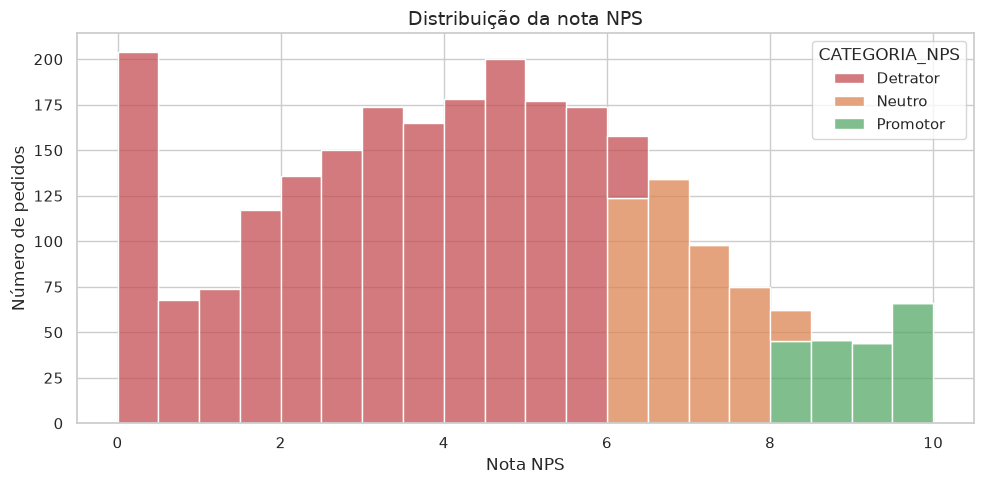

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_colunas_renomeadas, x='PONTUACAO_NPS', hue='CATEGORIA_NPS',
    hue_order=['Detrator', 'Neutro', 'Promotor'],
    palette={'Detrator': VERMELHO, 'Neutro': LARANJA, 'Promotor': VERDE},
    binwidth=0.5, multiple='stack', edgecolor='white',
)
plt.title('Distribuição da nota NPS', fontsize=14)
plt.xlabel('Nota NPS')
plt.ylabel('Número de pedidos')
plt.tight_layout()
salvar_figura('01_distribuicao_nps')
plt.show()

Com essa regra, **74,0%** dos pedidos são detratores, **17,9%** neutros e **8,0%** promotores. A nota média é **4,38/10**, e o NPS líquido é **−66 pontos**. Esses números descrevem apenas a base analisada; não são um benchmark do setor.

## 2. Perguntas do desafio

### 2.1 Quais fatores se associam mais à nota?

Vamos comparar a nota com as variáveis numéricas de perfil, pedido e operação usando Spearman (`ρ`). Esse indicador mostra se duas variáveis tendem a subir ou cair juntas; não mostra causa. Os valores-p são exploratórios, pois fazemos várias comparações.

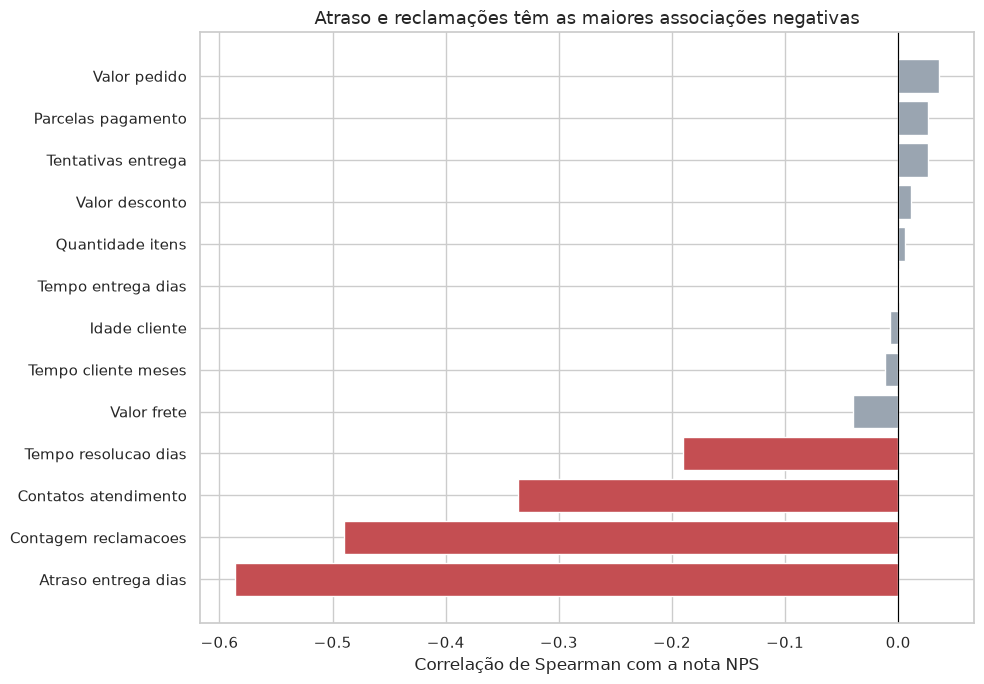

,Variável,rho,valor-p
0,VALOR_PEDIDO,0.036,0.0728
1,PARCELAS_PAGAMENTO,0.027,0.183
2,TENTATIVAS_ENTREGA,0.026,0.189
3,VALOR_DESCONTO,0.012,0.563
4,QUANTIDADE_ITENS,0.006,0.755
5,TEMPO_ENTREGA_DIAS,0.000,0.988
6,IDADE_CLIENTE,-0.007,0.71
7,TEMPO_CLIENTE_MESES,-0.012,0.56
8,VALOR_FRETE,-0.040,0.0481
9,TEMPO_RESOLUCAO_DIAS,-0.190,8.03e-22


PONTUACAO_CSAT_INTERNO: rho = 0.56
RECOMPRA_30D: rho = 0.49
Contatos com o atendimento x reclamações: rho = 0.74


In [10]:
colunas_numericas = [
    'IDADE_CLIENTE', 'TEMPO_CLIENTE_MESES', 'VALOR_PEDIDO', 'QUANTIDADE_ITENS', 'VALOR_DESCONTO',
    'PARCELAS_PAGAMENTO', 'VALOR_FRETE', 'TEMPO_ENTREGA_DIAS', 'ATRASO_ENTREGA_DIAS', 'TENTATIVAS_ENTREGA',
    'CONTATOS_ATENDIMENTO', 'TEMPO_RESOLUCAO_DIAS', 'CONTAGEM_RECLAMACOES',
]

linhas = []
for coluna in colunas_numericas:
    rho, p_valor = spearmanr(df_colunas_renomeadas['PONTUACAO_NPS'], df_colunas_renomeadas[coluna])
    linhas.append({'Variável': coluna, 'rho': rho, 'valor-p': p_valor})
rho_todas = pd.DataFrame(linhas).sort_values('rho', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 7))
cores = [VERMELHO if r < -0.1 else '#9AA5B1' for r in rho_todas['rho']]
plt.barh(rho_todas['Variável'].str.replace('_', ' ').str.capitalize(), rho_todas['rho'], color=cores)
plt.axvline(0, color='black', linewidth=0.8)
plt.gca().invert_yaxis()
plt.xlabel('Correlação de Spearman com a nota NPS')
plt.title('Atraso e reclamações têm as maiores associações negativas', fontsize=13)
plt.tight_layout()
salvar_figura('04_correlacao_todas_variaveis')
plt.show()

display(rho_todas.style.format({'rho': '{:.3f}', 'valor-p': '{:.3g}'}))

# Só pra comparar: as duas variáveis que NÃO usaria como "fator" porque são consequência da satisfação
for coluna in ['PONTUACAO_CSAT_INTERNO', 'RECOMPRA_30D']:
    rho, _ = spearmanr(df_colunas_renomeadas['PONTUACAO_NPS'], df_colunas_renomeadas[coluna])
    print(f'{coluna}: rho = {rho:.2f}')

rho_contatos_reclamacoes, _ = spearmanr(df_colunas_renomeadas['CONTATOS_ATENDIMENTO'], df_colunas_renomeadas['CONTAGEM_RECLAMACOES'])
print(f'Contatos com o atendimento x reclamações: rho = {rho_contatos_reclamacoes:.2f}')

### O que os dados mostram

- A nota tem associação negativa mais forte com **atraso** (`ρ ≈ −0,586`) e **reclamações** (`ρ ≈ −0,490`). Também há associação com contatos no atendimento (`ρ ≈ −0,336`) e tempo de resolução (`ρ ≈ −0,190`).
- Tentativas de entrega têm associação próxima de zero (`ρ ≈ +0,026`; `p ≈ 0,19`).
- Idade, tempo de relacionamento e valores do pedido têm associações pequenas nesta base.
- Reclamações e contatos caminham juntos (`ρ ≈ +0,736`), então esta análise não separa a contribuição de cada um.
- CSAT e recompra também se relacionam com a nota, mas podem refletir a própria experiência. Não os tratamos como fatores que a operação conhece antes dela.

### 2.2 Em quais situações há mais detratores?

O gráfico compara a proporção de detratores em cada situação. As barras incluem o número de pedidos e intervalos de confiança de 95% de Wilson. Repare especialmente no grupo sem reclamações, que é pequeno.

In [11]:
cenarios = {
    'Atraso na Entrega': 'TEVE_ATRASO',
    'Abriu Reclamação': 'TEVE_RECLAMACAO',
    'Mais de 1 Tentativa': 'MAIS_DE_1_TENTATIVA'
}

linhas_tabela = []
dados_grafico = {False: [], True: []}
for nome_cenario, coluna_flag in cenarios.items():
    linha = {'Fator Operacional': nome_cenario}
    for ocorreu, rotulo in [(False, 'Fluxo Ideal'), (True, 'Com Problema')]:
        grupo = df_colunas_renomeadas[df_colunas_renomeadas[coluna_flag] == ocorreu]
        taxa = grupo['DETRATOR'].mean() * 100
        ic_inf, ic_sup = intervalo_wilson(grupo['DETRATOR'].sum(), len(grupo))
        linha[f'Pedidos ({rotulo})'] = len(grupo)
        linha[f'Detratores % ({rotulo})'] = taxa
        linha[f'IC 95% ({rotulo})'] = f'{ic_inf * 100:.1f} a {ic_sup * 100:.1f}'
        dados_grafico[ocorreu].append((taxa, ic_inf * 100, ic_sup * 100, len(grupo)))
    linhas_tabela.append(linha)

df_taxa_detratores = pd.DataFrame(linhas_tabela).set_index('Fator Operacional')
print("Comparação da Geração de Detratores:")
display(df_taxa_detratores.round(1))

Comparação da Geração de Detratores:


,Pedidos (Fluxo Ideal),Detratores % (Fluxo Ideal),IC 95% (Fluxo Ideal),Pedidos (Com Problema),Detratores % (Com Problema),IC 95% (Com Problema)
Fator Operacional,,,,,,
Atraso na Entrega,277,36.5,31.0 a 42.3,2223,78.7,77.0 a 80.4
Abriu Reclamação,23,4.3,0.8 a 21.0,2477,74.7,72.9 a 76.4
Mais de 1 Tentativa,824,74.4,71.3 a 77.3,1676,73.9,71.7 a 75.9


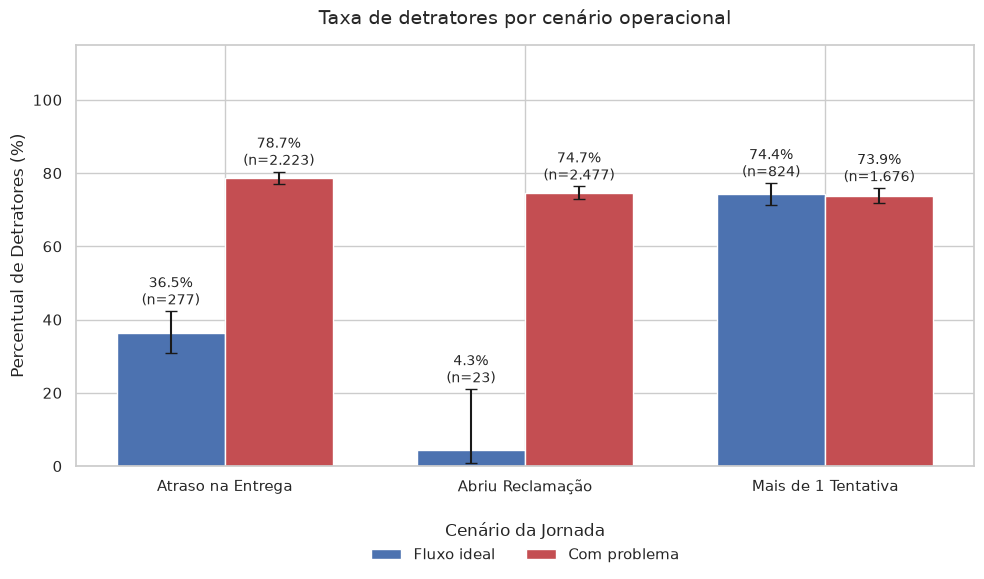

In [12]:
posicoes = np.arange(len(cenarios))
largura = 0.36

plt.figure(figsize=(10, 6))
for deslocamento, ocorreu, cor, rotulo in [(-0.5, False, AZUL, 'Fluxo ideal'), (0.5, True, VERMELHO, 'Com problema')]:
    taxas = [d[0] for d in dados_grafico[ocorreu]]
    erro_baixo = [d[0] - d[1] for d in dados_grafico[ocorreu]]
    erro_cima = [d[2] - d[0] for d in dados_grafico[ocorreu]]
    barras = plt.bar(posicoes + deslocamento * largura, taxas, largura, yerr=[erro_baixo, erro_cima], capsize=4, color=cor, label=rotulo)
    for barra, d in zip(barras, dados_grafico[ocorreu]):
        plt.annotate(f"{d[0]:.1f}%\n(n={d[3]:,})".replace(',', '.'), (barra.get_x() + barra.get_width() / 2, d[2]),
                     ha='center', xytext=(0, 5), textcoords='offset points', fontsize=10)

plt.title('Taxa de detratores por cenário operacional', fontsize=14, pad=15)
plt.ylabel('Percentual de Detratores (%)', fontsize=12)
plt.xticks(posicoes, list(cenarios.keys()), fontsize=11)
plt.ylim(0, 115)
plt.legend(title='Cenário da Jornada', loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.tight_layout()
salvar_figura('05_detratores_por_cenario')
plt.show()

A proporção de detratores é **36,5% sem atraso** e **78,7% com algum atraso**. Para exatamente um dia de atraso, é **59,7%**. Entre pedidos com reclamação, chega a **74,7%**; sem reclamação, é **4,3%**, mas esse grupo tem só **23 pedidos** e o intervalo é amplo (**0,8% a 21,0%**).

Mesmo sem atraso, mais de um terço dos pedidos é classificado como detrator. E, como quase todos têm reclamações registradas, a comparação com quem não tem registro é incerta. Essas diferenças não provam que um fator isolado causou a nota.

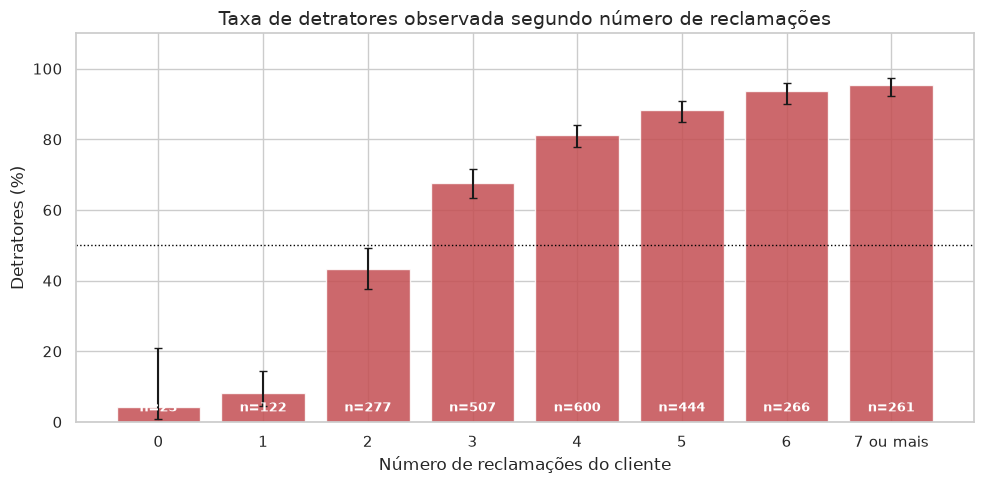

In [13]:
df_colunas_renomeadas['FAIXA_RECLAMACOES'] = pd.cut(
    df_colunas_renomeadas['CONTAGEM_RECLAMACOES'],
    bins=[-1, 0, 1, 2, 3, 4, 5, 6, 99],
    labels=['0', '1', '2', '3', '4', '5', '6', '7 ou mais'],
)
detratores_por_reclamacao = tabela_por_grupo(df_colunas_renomeadas, 'FAIXA_RECLAMACOES')

plt.figure(figsize=(10, 5))
taxas = detratores_por_reclamacao['Detratores (%)']
erro = [taxas - detratores_por_reclamacao['IC 95% inferior (%)'], detratores_por_reclamacao['IC 95% superior (%)'] - taxas]
plt.bar(detratores_por_reclamacao.index.astype(str), taxas, yerr=erro, capsize=3, color=VERMELHO, alpha=0.85)
for posicao, pedidos in enumerate(detratores_por_reclamacao['Pedidos']):
    plt.text(posicao, 3, f'n={int(pedidos)}', ha='center', color='white', fontsize=9, fontweight='bold')
plt.axhline(50, color='black', linestyle=':', linewidth=1)
plt.ylim(0, 110)
plt.xlabel('Número de reclamações do cliente')
plt.ylabel('Detratores (%)')
plt.title('Taxa de detratores observada segundo número de reclamações', fontsize=14)
plt.tight_layout()
salvar_figura('06_detratores_por_reclamacoes')
plt.show()

A proporção de detratores cresce junto com o número de reclamações: cerca de **8% com uma** (`n = 122`), **43% com duas** (`n = 277`), **68% com três** (`n = 507`) e **95% com sete ou mais** (`n = 261`). O padrão é descritivo e não prova causa.

A tabela seguinte cruza reclamações e atraso. As taxas mais extremas precisam ser lidas junto com o número de pedidos em cada combinação.

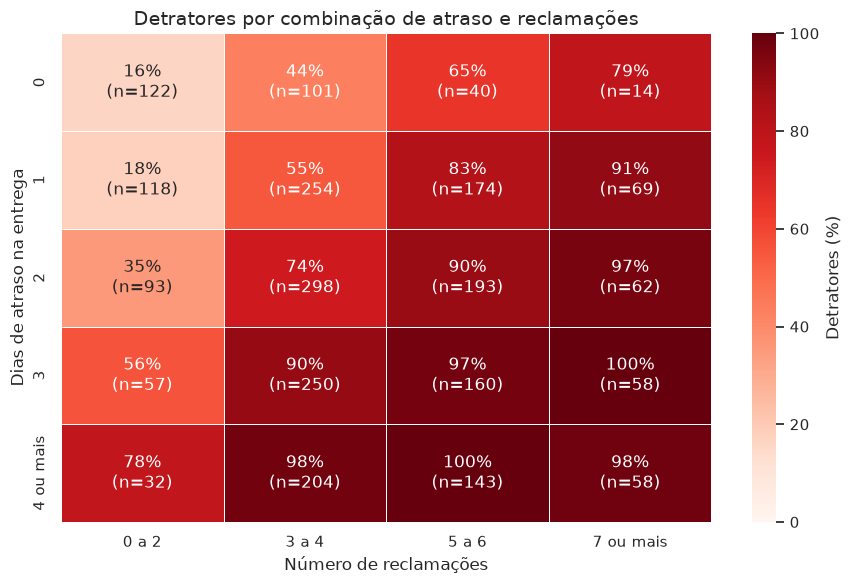

In [14]:
df_colunas_renomeadas['FAIXA_ATRASO'] = pd.cut(
    df_colunas_renomeadas['ATRASO_ENTREGA_DIAS'], bins=[-1, 0, 1, 2, 3, 99], labels=['0', '1', '2', '3', '4 ou mais']
)
df_colunas_renomeadas['FAIXA_RECLAMACOES_AGRUPADA'] = pd.cut(
    df_colunas_renomeadas['CONTAGEM_RECLAMACOES'], bins=[-1, 2, 4, 6, 99], labels=['0 a 2', '3 a 4', '5 a 6', '7 ou mais']
)

tabela_taxa = df_colunas_renomeadas.pivot_table(
    index='FAIXA_ATRASO', columns='FAIXA_RECLAMACOES_AGRUPADA', values='DETRATOR', aggfunc='mean', observed=True) * 100
tabela_pedidos = df_colunas_renomeadas.pivot_table(
    index='FAIXA_ATRASO', columns='FAIXA_RECLAMACOES_AGRUPADA', values='DETRATOR', aggfunc='count', observed=True)
anotacoes = tabela_taxa.round(0).astype(int).astype(str) + '%\n(n=' + tabela_pedidos.astype(int).astype(str) + ')'

plt.figure(figsize=(9, 6))
sns.heatmap(tabela_taxa, annot=anotacoes, fmt='', cmap='Reds', vmin=0, vmax=100, linewidths=0.5, cbar_kws={'label': 'Detratores (%)'})
plt.xlabel('Número de reclamações')
plt.ylabel('Dias de atraso na entrega')
plt.title('Detratores por combinação de atraso e reclamações', fontsize=14)
plt.tight_layout()
salvar_figura('07_heatmap_atraso_reclamacoes')
plt.show()

As proporções são maiores nas combinações com mais atraso e reclamações. Isso ajuda a apontar onde investigar, mas não prova que os dois fatores tenham efeitos independentes: a análise não controla outras diferenças entre os pedidos e algumas combinações têm poucos casos.

### 2.3 Como a nota muda com o atraso?

A maior queda média aparece entre nenhum atraso e um dia. A tabela e o gráfico mostram a nota, a proporção de detratores, o número de pedidos e o intervalo de confiança. Os grupos de atrasos longos são pequenos, então suas estimativas são menos estáveis.

In [15]:
resumo_atraso = tabela_por_grupo(df_colunas_renomeadas, 'ATRASO_ENTREGA_DIAS')
resumo_atraso['Queda da nota vs. dia anterior'] = resumo_atraso['NPS médio'].diff()
display(resumo_atraso.round(2))

# Quanto a nota cai, em média, a cada dia de atraso (reta ajustada)
reta = linregress(df_colunas_renomeadas['ATRASO_ENTREGA_DIAS'], df_colunas_renomeadas['PONTUACAO_NPS'])
print(f'Queda média: {reta.slope:.2f} ponto de NPS por dia de atraso (IC 95%: {reta.slope - 1.96 * reta.stderr:.2f} a {reta.slope + 1.96 * reta.stderr:.2f})')

,Pedidos,NPS médio,Detratores (%),IC 95% inferior (%),IC 95% superior (%),Queda da nota vs. dia anterior
ATRASO_ENTREGA_DIAS,,,,,,
0,277,6.86,36.46,31.01,42.28,NaN
1,615,5.55,59.67,55.75,63.48,-1.31
2,646,4.58,75.39,71.92,78.55,-0.97
3,525,3.44,89.71,86.82,92.03,-1.14
4,270,2.44,95.93,92.85,97.71,-0.99
5,116,1.48,99.14,95.28,99.85,-0.96
6,34,1.10,100.00,89.85,100.00,-0.38
7,14,0.29,100.00,78.47,100.00,-0.80
8,3,0.00,100.00,43.85,100.00,-0.29


Queda média: -1.03 ponto de NPS por dia de atraso (IC 95%: -1.09 a -0.98)


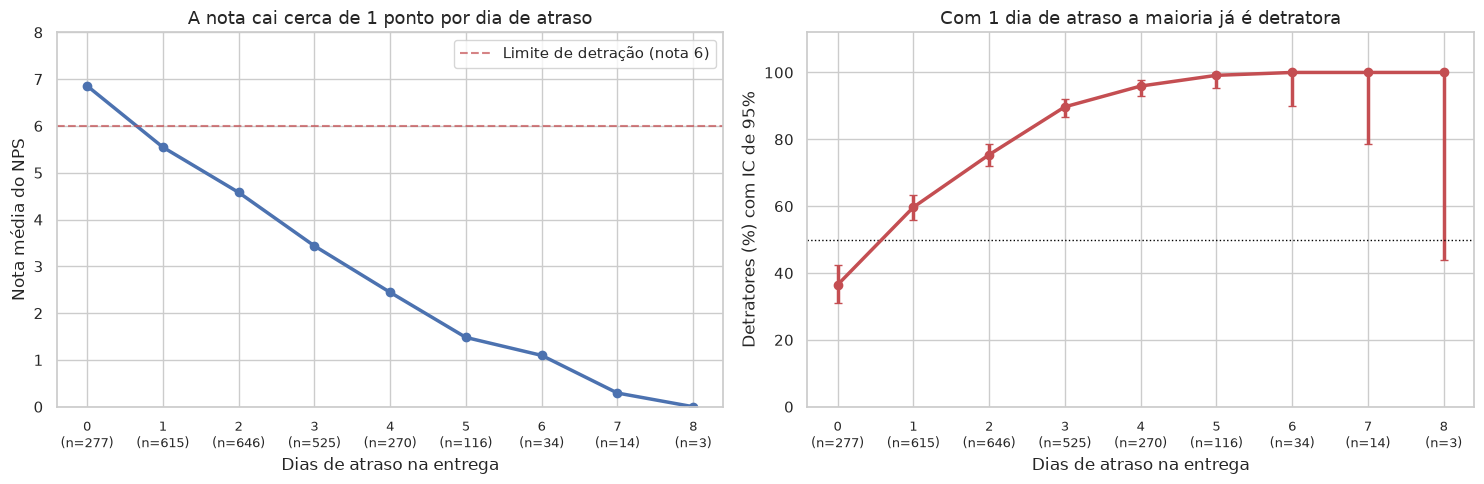

In [16]:
tabela_grafico = resumo_atraso.loc[0:8]
dias = tabela_grafico.index.to_numpy()
rotulos = [f'{d}\n(n={int(n)})' for d, n in zip(dias, tabela_grafico['Pedidos'])]

fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

# Nota média por dia de atraso
eixos[0].plot(dias, tabela_grafico['NPS médio'], marker='o', color=AZUL, linewidth=2.5)
eixos[0].axhline(6, color=VERMELHO, linestyle='--', alpha=0.7, label='Limite de detração (nota 6)')
eixos[0].set_title('A nota cai cerca de 1 ponto por dia de atraso', fontsize=13)
eixos[0].set_xlabel('Dias de atraso na entrega')
eixos[0].set_ylabel('Nota média do NPS')
eixos[0].set_xticks(dias)
eixos[0].set_xticklabels(rotulos, fontsize=9)
eixos[0].set_ylim(0, 8)
eixos[0].legend()

# Proporção de detratores, com intervalo de confiança
taxa = tabela_grafico['Detratores (%)']
erro = [taxa - tabela_grafico['IC 95% inferior (%)'], tabela_grafico['IC 95% superior (%)'] - taxa]
eixos[1].errorbar(dias, taxa, yerr=erro, marker='o', color=VERMELHO, linewidth=2.5, capsize=3)
eixos[1].axhline(50, color='black', linestyle=':', linewidth=1)
eixos[1].set_title('Com 1 dia de atraso a maioria já é detratora', fontsize=13)
eixos[1].set_xlabel('Dias de atraso na entrega')
eixos[1].set_ylabel('Detratores (%) com IC de 95%')
eixos[1].set_xticks(dias)
eixos[1].set_xticklabels(rotulos, fontsize=9)
eixos[1].set_ylim(0, 112)

plt.tight_layout()
salvar_figura('08_ponto_de_ruptura_atraso')
plt.show()

Sem atraso, a nota média é **6,86**; com um dia, **5,55**. A proporção de detratores sobe de **36,5%** para **59,7%**. Ela chega a cerca de **90%** com três dias de atraso.

O primeiro dia marca a maior queda observada, mas isso não define um limite universal. Nos atrasos mais longos há poucos pedidos — apenas **34** com seis dias e **3** com oito —, então os resultados ficam mais incertos.

### 2.4 Que tipo de cliente tem NPS mais alto ou mais baixo?

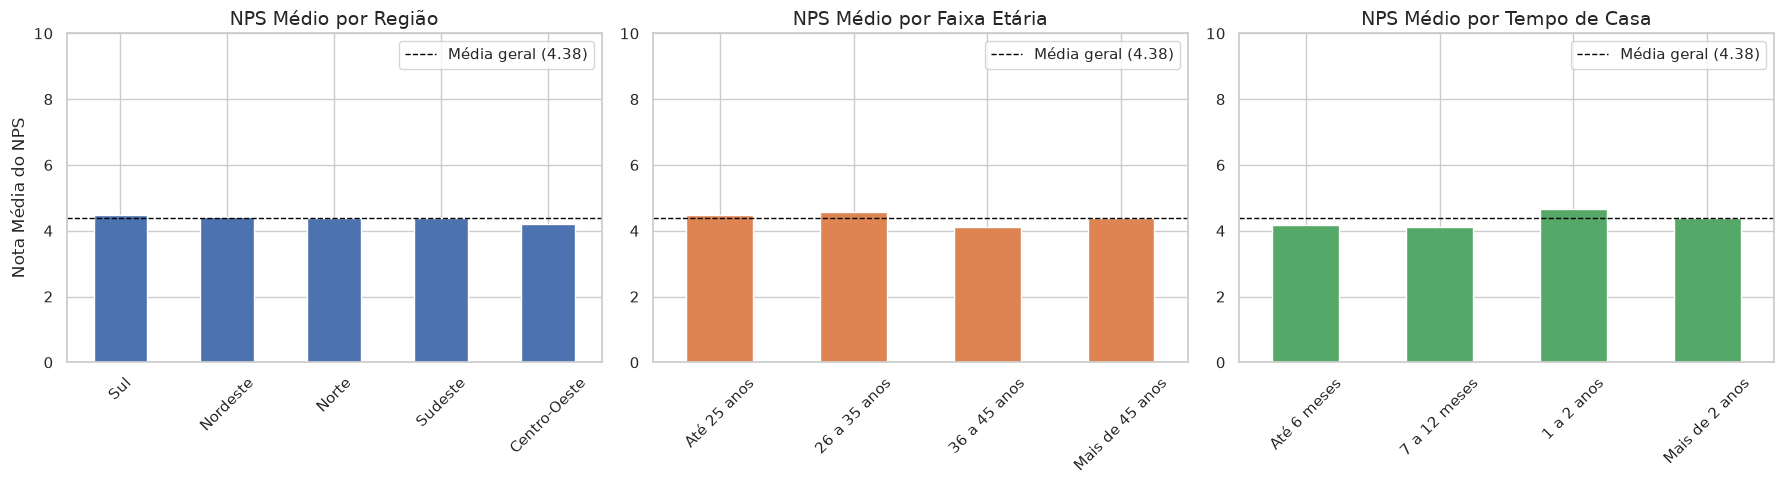

In [17]:
# 1. NPS por Região
nps_regiao = df_colunas_renomeadas.groupby('REGIAO_CLIENTE')['PONTUACAO_NPS'].mean().sort_values(ascending=False)

# 2. NPS por Faixa de Idade
# Criação das faixas etárias
bins_idade = [0, 25, 35, 45, 120]
labels_idade = ['Até 25 anos', '26 a 35 anos', '36 a 45 anos', 'Mais de 45 anos']
df_colunas_renomeadas['FAIXA_IDADE'] = pd.cut(df_colunas_renomeadas['IDADE_CLIENTE'], bins=bins_idade, labels=labels_idade)
nps_idade = df_colunas_renomeadas.groupby('FAIXA_IDADE', observed=False)['PONTUACAO_NPS'].mean()

# 3. NPS por Tempo de Relacionamento (Fidelidade)
# Criação das faixas de tempo de casa (em meses)
bins_tempo = [0, 6, 12, 24, 999]
labels_tempo = ['Até 6 meses', '7 a 12 meses', '1 a 2 anos', 'Mais de 2 anos']
df_colunas_renomeadas['FAIXA_TEMPO'] = pd.cut(df_colunas_renomeadas['TEMPO_CLIENTE_MESES'], bins=bins_tempo, labels=labels_tempo)
nps_tempo = df_colunas_renomeadas.groupby('FAIXA_TEMPO', observed=False)['PONTUACAO_NPS'].mean()

# --- Criando o Painel com os 3 Gráficos Lado a Lado ---
media_geral_nps = df_colunas_renomeadas['PONTUACAO_NPS'].mean()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico de Região
nps_regiao.plot(kind='bar', ax=axes[0], color=AZUL, label='_nolegend_')
axes[0].set_title('NPS Médio por Região', fontsize=14)
axes[0].set_ylabel('Nota Média do NPS')
axes[0].set_ylim(0, 10)  # Trava o eixo Y até 10 para ficar na escala do NPS
axes[0].tick_params(axis='x', rotation=45)

# Gráfico de Idade
nps_idade.plot(kind='bar', ax=axes[1], color=LARANJA, label='_nolegend_')
axes[1].set_title('NPS Médio por Faixa Etária', fontsize=14)
axes[1].set_ylim(0, 10)
axes[1].tick_params(axis='x', rotation=45)

# Gráfico de Tempo de Casa
nps_tempo.plot(kind='bar', ax=axes[2], color=VERDE, label='_nolegend_')
axes[2].set_title('NPS Médio por Tempo de Casa', fontsize=14)
axes[2].set_ylim(0, 10)
axes[2].tick_params(axis='x', rotation=45)

# Linha com a média geral, para comparar cada barra
for eixo in axes:
    eixo.set_xlabel('')
    eixo.axhline(media_geral_nps, color='black', linestyle='--', linewidth=1, label=f'Média geral ({media_geral_nps:.2f})')
    eixo.legend(loc='upper right')

plt.tight_layout()
salvar_figura('09_nps_por_perfil')
plt.show()

A tabela mostra quantos pedidos há em cada perfil e a nota média. Também usamos o teste de Kruskal–Wallis para comparar os grupos. Um resultado sem significância não prova que os grupos sejam iguais.

In [18]:
grupos_perfil = [('Região', 'REGIAO_CLIENTE'), ('Faixa etária', 'FAIXA_IDADE'), ('Tempo de relacionamento', 'FAIXA_TEMPO')]
resumo_perfil = []
for nome, coluna in grupos_perfil:
    tabela = df_colunas_renomeadas.groupby(coluna, observed=True)['PONTUACAO_NPS'].agg(['size', 'mean']).reset_index()
    teste = kruskal(*(grupo['PONTUACAO_NPS'].to_numpy() for _, grupo in df_colunas_renomeadas.groupby(coluna, observed=True)))
    resumo_perfil.append({'Dimensão': nome, 'H de Kruskal-Wallis': teste.statistic, 'valor-p': teste.pvalue})
    tabela.insert(0, 'Dimensão', nome)
    resumo_perfil[-1]['Grupos'] = len(tabela)
    display(tabela.rename(columns={coluna: 'Grupo', 'size': 'Pedidos', 'mean': 'NPS médio'}).round(2))
display(pd.DataFrame(resumo_perfil).style.format({'H de Kruskal-Wallis': '{:.2f}', 'valor-p': '{:.3f}'}))

# Também olhei idade e tempo de relacionamento sem dividir em faixas
for coluna in ['IDADE_CLIENTE', 'TEMPO_CLIENTE_MESES']:
    rho, p_valor = spearmanr(df_colunas_renomeadas[coluna], df_colunas_renomeadas['PONTUACAO_NPS'])
    print(f'{coluna}: rho = {rho:.3f} (valor-p = {p_valor:.2f})')

,Dimensão,Grupo,Pedidos,NPS médio
0,Região,Centro-Oeste,468,4.21
1,Região,Nordeste,485,4.42
2,Região,Norte,506,4.38
3,Região,Sudeste,520,4.37
4,Região,Sul,521,4.49


,Dimensão,Grupo,Pedidos,NPS médio
0,Faixa etária,Até 25 anos,389,4.48
1,Faixa etária,26 a 35 anos,465,4.56
2,Faixa etária,36 a 45 anos,517,4.12
3,Faixa etária,Mais de 45 anos,1129,4.39


,Dimensão,Grupo,Pedidos,NPS médio
0,Tempo de relacionamento,Até 6 meses,122,4.17
1,Tempo de relacionamento,7 a 12 meses,120,4.12
2,Tempo de relacionamento,1 a 2 anos,247,4.65
3,Tempo de relacionamento,Mais de 2 anos,2011,4.37


,Dimensão,H de Kruskal-Wallis,valor-p,Grupos
0,Região,3.38,0.497,5
1,Faixa etária,7.50,0.058,4
2,Tempo de relacionamento,4.78,0.189,4


IDADE_CLIENTE: rho = -0.007 (valor-p = 0.71)
TEMPO_CLIENTE_MESES: rho = -0.012 (valor-p = 0.56)


As médias são parecidas entre regiões, faixas de idade e tempo de relacionamento. Não aparece diferença clara por **região** (`p ≈ 0,497`) ou **tempo de relacionamento** (`p ≈ 0,189`). A faixa etária fica perto, mas acima, do corte de 5% (`p ≈ 0,058`).

Com estes dados, não há motivo para priorizar segmentação por perfil. Isso não significa que diferenças nunca existam; apenas que não ficaram claras nesta amostra.

### 2.5 Como a recompra observada varia por categoria de NPS?

Vamos comparar a recompra em 30 dias com as categorias de NPS. Essa relação é descritiva: sozinha, não mostra que uma nota alta leva à recompra. Também precisamos confirmar como o campo de recompra foi criado.

Taxa de Recompra em 30 Dias por Categoria NPS:


CATEGORIA_NPS
Detrator      0.0%
Neutro        3.8%
Promotor    100.0%
Name: RECOMPRA_30D, dtype: str

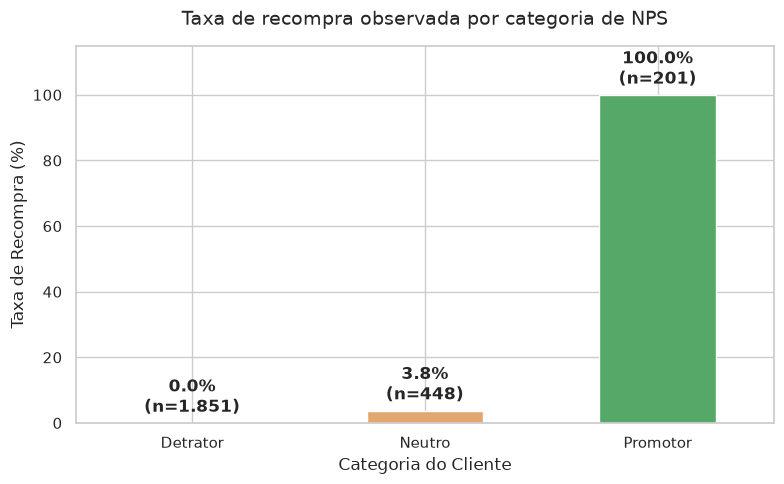

In [19]:
# Taxa de recompra (média * 100), na ordem do pior para o melhor
taxa_recompra = df_colunas_renomeadas.groupby('CATEGORIA_NPS', observed=True)['RECOMPRA_30D'].mean() * 100
pedidos_categoria = df_colunas_renomeadas['CATEGORIA_NPS'].value_counts()

print("Taxa de Recompra em 30 Dias por Categoria NPS:")
display(taxa_recompra.round(1).astype(str) + '%')

# Gráfico de Barras com cores semânticas
plt.figure(figsize=(8, 5))
cores = [VERMELHO, '#E2A76F', VERDE]  # Vermelho, Laranja/Amarelo, Verde
ax = taxa_recompra.plot(kind='bar', color=cores)

plt.title('Taxa de recompra observada por categoria de NPS', fontsize=14, pad=15)
plt.xlabel('Categoria do Cliente', fontsize=12)
plt.ylabel('Taxa de Recompra (%)', fontsize=12)
plt.xticks(rotation=0)
plt.ylim(0, 115)

# Adiciona as porcentagens exatas e o número de pedidos no topo das barras
for barra, categoria in zip(ax.patches, taxa_recompra.index):
    ax.annotate(f"{barra.get_height():.1f}%\n(n={pedidos_categoria[categoria]:,})".replace(',', '.'),
                (barra.get_x() + barra.get_width() / 2., barra.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold')

plt.tight_layout()
salvar_figura('10_recompra_por_categoria')
plt.show()

In [20]:
print('Pedidos por categoria e recompra (0 = não, 1 = sim):')
display(pd.crosstab(df_colunas_renomeadas['CATEGORIA_NPS'], df_colunas_renomeadas['RECOMPRA_30D'], margins=True))
recompra_bate_com_nps = (df_colunas_renomeadas['RECOMPRA_30D'] == (df_colunas_renomeadas['PONTUACAO_NPS'] >= 8).astype(int)).all()
print(f'A recompra coincide com a regra PONTUACAO_NPS >= 8 em todos os pedidos? {recompra_bate_com_nps}')

Pedidos por categoria e recompra (0 = não, 1 = sim):


RECOMPRA_30D,0,1,All
CATEGORIA_NPS,,,
Detrator,1851,0,1851
Neutro,431,17,448
Promotor,0,201,201
All,2282,218,2500


A recompra coincide com a regra PONTUACAO_NPS >= 8 em todos os pedidos? True


Nesta base, a recompra coincide exatamente com `nps_score >= 8`. Isso sugere que uma variável pode ter sido derivada da outra. Até confirmar a origem do dado, essas taxas não devem ser usadas como medida de retenção ou retorno financeiro.

### 2.6 O que aparece nos dados de atendimento?

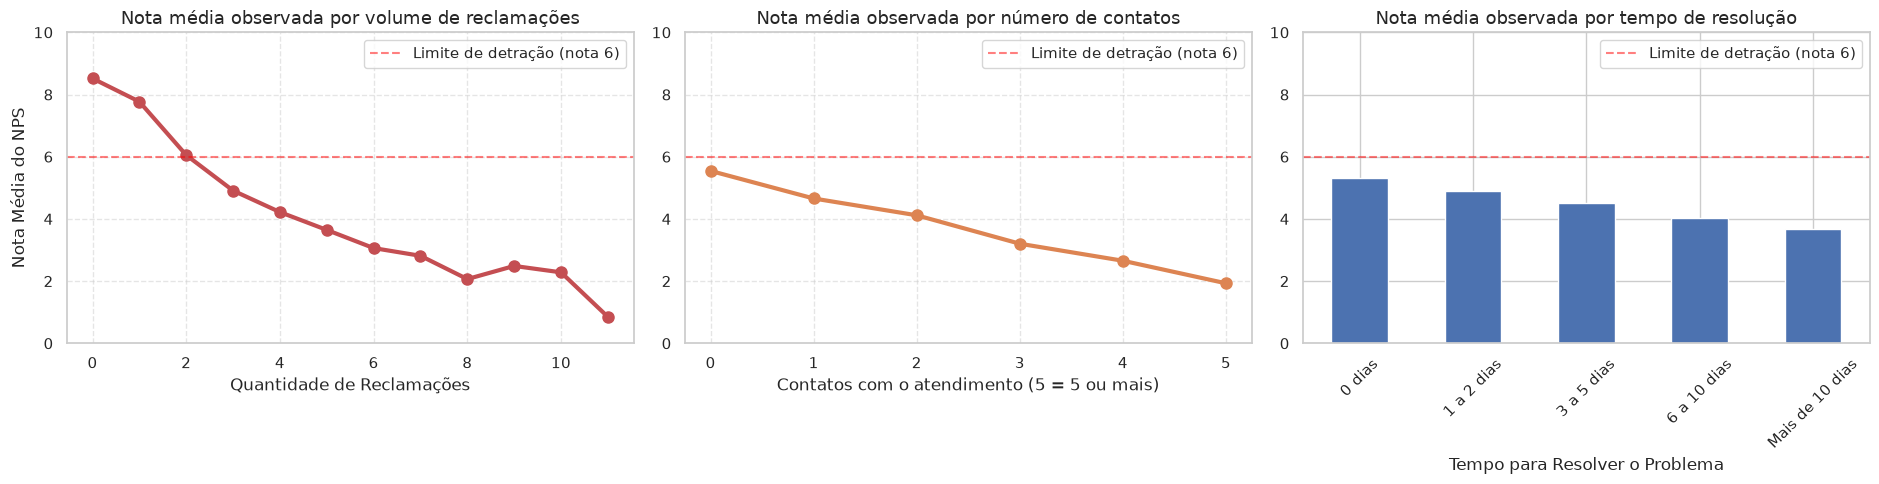

In [21]:
# 1. Agrupar NPS por Quantidade de Reclamações
nps_por_reclamacao = df_colunas_renomeadas.groupby('CONTAGEM_RECLAMACOES')['PONTUACAO_NPS'].mean()

# 2. NPS por número de contatos com o atendimento (5 = cinco ou mais)
contatos_agrupados = df_colunas_renomeadas['CONTATOS_ATENDIMENTO'].clip(upper=5)
nps_por_contatos = df_colunas_renomeadas.groupby(contatos_agrupados)['PONTUACAO_NPS'].mean()

# 3. Criar faixas para o Tempo de Resolução e calcular a média do NPS
bins_tempo = [-1, 0, 2, 5, 10, 999]  # -1 a 0 garante que quem teve 0 dias de resolução entre na primeira faixa
labels_tempo = ['0 dias', '1 a 2 dias', '3 a 5 dias', '6 a 10 dias', 'Mais de 10 dias']

df_colunas_renomeadas['FAIXA_TEMPO_RESOLUCAO'] = pd.cut(
    df_colunas_renomeadas['TEMPO_RESOLUCAO_DIAS'],
    bins=bins_tempo,
    labels=labels_tempo
)

nps_por_tempo = df_colunas_renomeadas.groupby('FAIXA_TEMPO_RESOLUCAO', observed=False)['PONTUACAO_NPS'].mean()

# --- Criando o Painel com 3 Gráficos Lado a Lado ---
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Gráfico 1: Impacto das Reclamações
nps_por_reclamacao.plot(kind='line', marker='o', ax=axes[0], color=VERMELHO, linewidth=3, markersize=8, label='_nolegend_')
axes[0].set_title('Nota média observada por volume de reclamações', fontsize=13)
axes[0].set_ylabel('Nota Média do NPS')
axes[0].set_xlabel('Quantidade de Reclamações')

# Gráfico 2: Impacto dos contatos com o atendimento
nps_por_contatos.plot(kind='line', marker='o', ax=axes[1], color=LARANJA, linewidth=3, markersize=8, label='_nolegend_')
axes[1].set_title('Nota média observada por número de contatos', fontsize=13)
axes[1].set_xlabel('Contatos com o atendimento (5 = 5 ou mais)')

# Gráfico 3: Impacto do Tempo de Resolução
nps_por_tempo.plot(kind='bar', ax=axes[2], color=AZUL, label='_nolegend_')
axes[2].set_title('Nota média observada por tempo de resolução', fontsize=13)
axes[2].set_xlabel('Tempo para Resolver o Problema')
axes[2].tick_params(axis='x', rotation=45)

for eixo in axes:
    eixo.set_ylim(0, 10)
    eixo.axhline(y=6, color='red', linestyle='--', alpha=0.5, label='Limite de detração (nota 6)')
    eixo.legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
salvar_figura('11_atendimento_gargalo')
plt.show()

O gráfico resume a nota média por número de reclamações, contatos e tempo de resolução. As faixas mais altas têm menos pedidos; consulte as contagens na tabela antes de interpretar esses valores.

In [22]:
print('Por número de reclamações:')
display(tabela_por_grupo(df_colunas_renomeadas, 'CONTAGEM_RECLAMACOES').round(1))
print('Por tempo de resolução:')
display(tabela_por_grupo(df_colunas_renomeadas, 'FAIXA_TEMPO_RESOLUCAO').round(1))

Por número de reclamações:


,Pedidos,NPS médio,Detratores (%),IC 95% inferior (%),IC 95% superior (%)
CONTAGEM_RECLAMACOES,,,,,
0,23,8.5,4.3,0.8,21.0
1,122,7.8,8.2,4.5,14.4
2,277,6.1,43.3,37.6,49.2
3,507,4.9,67.7,63.5,71.6
4,600,4.2,81.2,77.8,84.1
5,444,3.6,88.3,85.0,91.0
6,266,3.1,93.6,90.0,96.0
7,169,2.8,93.5,88.7,96.3
8,63,2.1,100.0,94.3,100.0


Por tempo de resolução:


,Pedidos,NPS médio,Detratores (%),IC 95% inferior (%),IC 95% superior (%)
FAIXA_TEMPO_RESOLUCAO,,,,,
0 dias,208,5.3,60.1,53.3,66.5
1 a 2 dias,421,4.9,66.3,61.6,70.6
3 a 5 dias,619,4.5,73.2,69.6,76.5
6 a 10 dias,1038,4.0,78.4,75.8,80.8
Mais de 10 dias,214,3.7,84.1,78.6,88.4


- **Reclamações:** a nota média é 7,77 com uma reclamação, 6,05 com duas e 4,91 com três. É uma associação observada; a contagem pode não significar chamados reabertos.
- **Tempo de resolução:** a média vai de 5,32 no mesmo dia a cerca de 3,7 acima de dez dias. Isso não prova que reduzir o prazo, sozinho, recupere a satisfação.
- **Contatos:** a nota tende a cair nos grupos com mais contatos. Como contatos e reclamações estão relacionados (`ρ ≈ 0,736`), não dá para separar os dois efeitos aqui.
- **A base tem pouca referência sem problema registrado:** 99,1% dos pedidos têm ao menos uma reclamação.

## 3. Conclusão e próximos passos

Atrasos e reclamações são os melhores pontos de partida para conversar com logística e atendimento. Antes de decidir uma ação, porém, precisamos confirmar as definições e inconsistências da base. Depois, vale repetir a análise com dados reais e testar qualquer mudança em um piloto.

### Resumo por pergunta de negócio

| Pergunta | Resultado nesta amostra | Cautela principal |
|---|---|---|
| Quais fatores mais se associam à nota? | Atraso (ρ = −0,586), reclamações (−0,490), contatos (−0,336) e tempo de resolução (−0,190). | Associações bivariadas; contatos e reclamações são correlacionados. |
| Como varia a detração? | 36,5% sem atraso, 59,7% com exatamente 1 dia e 78,7% com qualquer atraso; a taxa cresce com reclamações. | Comparações não causais; só 23 pedidos sem reclamação. |
| Há ponto de ruptura logística? | Maior queda média entre 0 dias (6,86) e 1 dia (5,55); cerca de 1 ponto a menos por dia na tendência observada. | Não é um limiar universal; grupos com atrasos longos são pequenos. |
| Há diferenças por perfil? | Não houve evidência clara por região (`p ≈ 0,497`) ou tempo (`p ≈ 0,189`); faixa etária ficou próxima do limiar (`p ≈ 0,058`). | Ausência de significância não prova equivalência. |
| O que diz a recompra? | `repeat_purchase_30d` coincide exatamente com `nps_score >= 8`. | Não usar como medida independente de retenção sem validar a origem. |
| O modelo foi treinado? | Não; esta entrega é uma EDA. | Definir o momento de previsão e validar dados antes de iniciar modelagem. |

### Limitações

- **Qualidade e origem:** 121 registros têm atraso maior que o tempo de entrega; em 35, o desconto supera o valor do pedido. A recompra coincide exatamente com um corte do NPS. Esses pontos exigem validação com a fonte.
- **Associação não é causalidade:** as análises são observacionais e não controlam fatores de confusão; não provam que agir sobre atraso ou atendimento aumentará a nota.
- **Sem dimensão temporal ou processo de pesquisa:** não há datas para avaliar sazonalidade ou evolução; também não se conhece a seleção de respondentes e não respondentes.
- **Grupos pequenos:** apenas 23 pedidos não têm reclamações e poucos pedidos têm atrasos longos; suas proporções são menos precisas.
- **Generalização:** os resultados descrevem apenas este arquivo e não devem ser tratados como estimativas de toda a carteira ou do setor.

### Próximos passos

1. Validar com a origem as definições de tempo de entrega, atraso, desconto, reclamações e recompra.
2. Repetir a análise com dados reais, datados, com o processo de convite e resposta à pesquisa documentado.
3. Se a modelagem for priorizada, definir o instante de previsão e excluir variáveis indisponíveis naquele momento ou derivadas da satisfação.
4. Comparar qualquer modelo com um baseline e avaliar uma intervenção em piloto antes de estimar retorno financeiro.